In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

In [3]:
df_train = pd.read_csv(r"C:\Users\Thulie\Desktop\house_price_prediction\data\train.csv")
df_train.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
df_test = pd.read_csv(r"C:\Users\Thulie\Desktop\house_price_prediction\data\test.csv")
df_test.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [7]:
print(f'Training data shape: {df_train.shape}')
print(f'Testing data shape: {df_test.shape}')

Training data shape: (1460, 81)
Testing data shape: (1459, 80)


In [8]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [9]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1455 non-null   str    
 3   LotFrontage    1232 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   str    
 6   Alley          107 non-null    str    
 7   LotShape       1459 non-null   str    
 8   LandContour    1459 non-null   str    
 9   Utilities      1457 non-null   str    
 10  LotConfig      1459 non-null   str    
 11  LandSlope      1459 non-null   str    
 12  Neighborhood   1459 non-null   str    
 13  Condition1     1459 non-null   str    
 14  Condition2     1459 non-null   str    
 15  BldgType       1459 non-null   str    
 16  HouseStyle     1459 non-null   str    
 17  OverallQual    1459 non-null   int64  
 18  OverallCond    1459

In [10]:
df_test.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [11]:
new_column_names = [
    "property_id",
    "dwelling_class",
    "zoning_classification",
    "street_frontage",
    "lot_area",
    "road_access_type",
    "alley_access_type",
    "lot_shape",
    "land_contour",
    "utilities_available",
    "lot_configuration",
    "land_slope",
    "neighborhood",
    "proximity_condition_1",
    "proximity_condition_2",
    "building_type",
    "house_style",
    "overall_quality",
    "overall_condition",
    "year_built",
    "year_remodeled",
    "roof_style",
    "roof_material",
    "primary_exterior_material",
    "secondary_exterior_material",
    "masonry_veneer_type",
    "masonry_veneer_area",
    "exterior_quality",
    "exterior_condition",
    "foundation_type",
    "basement_quality",
    "basement_condition",
    "basement_exposure",
    "basement_finished_type_1",
    "basement_finished_area_1",
    "basement_finished_type_2",
    "basement_finished_area_2",
    "basement_unfinished_area",
    "total_basement_area",
    "heating_type",
    "heating_quality",
    "central_air_conditioning",
    "electrical_system",
    "first_floor_area",
    "second_floor_area",
    "low_quality_finished_area",
    "above_ground_living_area",
    "basement_full_bathrooms",
    "basement_half_bathrooms",
    "full_bathrooms",
    "half_bathrooms",
    "bedrooms_above_ground",
    "kitchens_above_ground",
    "kitchen_quality",
    "total_rooms_above_ground",
    "home_functionality",
    "number_of_fireplaces",
    "fireplace_quality",
    "garage_type",
    "garage_year_built",
    "garage_finish",
    "garage_capacity",
    "garage_area",
    "garage_quality",
    "garage_condition",
    "driveway_surface",
    "wood_deck_area",
    "open_porch_area",
    "enclosed_porch_area",
    "three_season_porch_area",
    "screen_porch_area",
    "pool_area",
    "pool_quality",
    "fence_quality",
    "miscellaneous_feature",
    "miscellaneous_feature_value",
    "month_sold",
    "year_sold",
    "sale_type",
    "sale_condition"
]

In [12]:
# Rename training dataset
df_train.columns = new_column_names + ["sale_price"]

# Rename testing dataset
df_test.columns = new_column_names

In [13]:
print(sorted(df_train["neighborhood"].dropna().unique().tolist()))

['Blmngtn', 'Blueste', 'BrDale', 'BrkSide', 'ClearCr', 'CollgCr', 'Crawfor', 'Edwards', 'Gilbert', 'IDOTRR', 'MeadowV', 'Mitchel', 'NAmes', 'NPkVill', 'NWAmes', 'NoRidge', 'NridgHt', 'OldTown', 'SWISU', 'Sawyer', 'SawyerW', 'Somerst', 'StoneBr', 'Timber', 'Veenker']


In [15]:
categorical_features = df_train.select_dtypes(
    include=["str"]
).columns.tolist()

for col in categorical_features:
    print(f"\n{col}:")
    print(df_train[col].dropna().unique().tolist())


zoning_classification:
['RL', 'RM', 'C (all)', 'FV', 'RH']

road_access_type:
['Pave', 'Grvl']

alley_access_type:
['Grvl', 'Pave']

lot_shape:
['Reg', 'IR1', 'IR2', 'IR3']

land_contour:
['Lvl', 'Bnk', 'Low', 'HLS']

utilities_available:
['AllPub', 'NoSeWa']

lot_configuration:
['Inside', 'FR2', 'Corner', 'CulDSac', 'FR3']

land_slope:
['Gtl', 'Mod', 'Sev']

neighborhood:
['CollgCr', 'Veenker', 'Crawfor', 'NoRidge', 'Mitchel', 'Somerst', 'NWAmes', 'OldTown', 'BrkSide', 'Sawyer', 'NridgHt', 'NAmes', 'SawyerW', 'IDOTRR', 'MeadowV', 'Edwards', 'Timber', 'Gilbert', 'StoneBr', 'ClearCr', 'NPkVill', 'Blmngtn', 'BrDale', 'SWISU', 'Blueste']

proximity_condition_1:
['Norm', 'Feedr', 'PosN', 'Artery', 'RRAe', 'RRNn', 'RRAn', 'PosA', 'RRNe']

proximity_condition_2:
['Norm', 'Artery', 'RRNn', 'Feedr', 'PosN', 'PosA', 'RRAn', 'RRAe']

building_type:
['1Fam', '2fmCon', 'Duplex', 'TwnhsE', 'Twnhs']

house_style:
['2Story', '1Story', '1.5Fin', '1.5Unf', 'SFoyer', 'SLvl', '2.5Unf', '2.5Fin']

roof_s

In [101]:
df_train.head()

,property_id,dwelling_class,zoning_classification,street_frontage,lot_area,road_access_type,alley_access_type,lot_shape,land_contour,utilities_available,...,pool_area,pool_quality,fence_quality,miscellaneous_feature,miscellaneous_feature_value,month_sold,year_sold,sale_type,sale_condition,sale_price
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [102]:
df_test.head()

,property_id,dwelling_class,zoning_classification,street_frontage,lot_area,road_access_type,alley_access_type,lot_shape,land_contour,utilities_available,...,screen_porch_area,pool_area,pool_quality,fence_quality,miscellaneous_feature,miscellaneous_feature_value,month_sold,year_sold,sale_type,sale_condition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [103]:
df_train.describe()

,property_id,dwelling_class,street_frontage,lot_area,overall_quality,overall_condition,year_built,year_remodeled,masonry_veneer_area,basement_finished_area_1,...,wood_deck_area,open_porch_area,enclosed_porch_area,three_season_porch_area,screen_porch_area,pool_area,miscellaneous_feature_value,month_sold,year_sold,sale_price
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [104]:
df_test.describe()

,property_id,dwelling_class,street_frontage,lot_area,overall_quality,overall_condition,year_built,year_remodeled,masonry_veneer_area,basement_finished_area_1,...,garage_area,wood_deck_area,open_porch_area,enclosed_porch_area,three_season_porch_area,screen_porch_area,pool_area,miscellaneous_feature_value,month_sold,year_sold
count,1459.000000,1459.000000,1232.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1444.000000,1458.000000,...,1458.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000
mean,2190.000000,57.378341,68.580357,9819.161069,6.078821,5.553804,1971.357779,1983.662783,100.709141,439.203704,...,472.768861,93.174777,48.313914,24.243317,1.794380,17.064428,1.744345,58.167923,6.104181,2007.769705
std,421.321334,42.746880,22.376841,4955.517327,1.436812,1.113740,30.390071,21.130467,177.625900,455.268042,...,217.048611,127.744882,68.883364,67.227765,20.207842,56.609763,30.491646,630.806978,2.722432,1.301740
min,1461.000000,20.000000,21.000000,1470.000000,1.000000,1.000000,1879.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000
25%,1825.500000,20.000000,58.000000,7391.000000,5.000000,5.000000,1953.000000,1963.000000,0.000000,0.000000,...,318.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000
50%,2190.000000,50.000000,67.000000,9399.000000,6.000000,5.000000,1973.000000,1992.000000,0.000000,350.500000,...,480.000000,0.000000,28.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000
75%,2554.500000,70.000000,80.000000,11517.500000,7.000000,6.000000,2001.000000,2004.000000,164.000000,753.500000,...,576.000000,168.000000,72.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000
max,2919.000000,190.000000,200.000000,56600.000000,10.000000,9.000000,2010.000000,2010.000000,1290.000000,4010.000000,...,1488.000000,1424.000000,742.000000,1012.000000,360.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000


In [105]:
null_counts_train = df_train.isnull().sum()
null_counts_test = df_test.isnull().sum()
print(f"missing value counts in training dataset: \n {null_counts_train[null_counts_train > 0].sort_values(ascending = False)}")
print("\n=========================================================================================\n")
print(f"missing value counts in testing dataset: \n {null_counts_test[null_counts_test > 0].sort_values(ascending = False)}")

missing value counts in training dataset: 
 pool_quality                1453
miscellaneous_feature       1406
alley_access_type           1369
fence_quality               1179
masonry_veneer_type          872
fireplace_quality            690
street_frontage              259
garage_type                   81
garage_year_built             81
garage_finish                 81
garage_quality                81
garage_condition              81
basement_exposure             38
basement_finished_type_2      38
basement_quality              37
basement_condition            37
basement_finished_type_1      37
masonry_veneer_area            8
electrical_system              1
dtype: int64


missing value counts in testing dataset: 
 pool_quality                   1456
miscellaneous_feature          1408
alley_access_type              1352
fence_quality                  1169
masonry_veneer_type             894
fireplace_quality               730
street_frontage                 227
garage_quality     

In [106]:
percentage_null_counts_train= null_counts_train/df_train.shape[0] * 100
percentage_null_counts_train[percentage_null_counts_train > 0].sort_values(ascending = False)

pool_quality                99.520548
miscellaneous_feature       96.301370
alley_access_type           93.767123
fence_quality               80.753425
masonry_veneer_type         59.726027
fireplace_quality           47.260274
street_frontage             17.739726
garage_type                  5.547945
garage_year_built            5.547945
garage_finish                5.547945
garage_quality               5.547945
garage_condition             5.547945
basement_exposure            2.602740
basement_finished_type_2     2.602740
basement_quality             2.534247
basement_condition           2.534247
basement_finished_type_1     2.534247
masonry_veneer_area          0.547945
electrical_system            0.068493
dtype: float64

In [107]:
percentage_null_counts_test = null_counts_test/df_test.shape[0] * 100
percentage_null_counts_test[percentage_null_counts_test > 0].sort_values(ascending = False)

pool_quality                   99.794380
miscellaneous_feature          96.504455
alley_access_type              92.666210
fence_quality                  80.123372
masonry_veneer_type            61.274846
fireplace_quality              50.034270
street_frontage                15.558602
garage_quality                  5.346127
garage_condition                5.346127
garage_year_built               5.346127
garage_finish                   5.346127
garage_type                     5.209047
basement_condition              3.084304
basement_quality                3.015764
basement_exposure               3.015764
basement_finished_type_1        2.878684
basement_finished_type_2        2.878684
masonry_veneer_area             1.028101
zoning_classification           0.274160
home_functionality              0.137080
basement_full_bathrooms         0.137080
utilities_available             0.137080
basement_half_bathrooms         0.137080
primary_exterior_material       0.068540
secondary_exteri

In [108]:
# Categorical columns where NaN means absence(None)
absence_categorical = [
    "pool_quality",
    "miscellaneous_feature",
    "alley_access_type",
    "fence_quality",
    "fireplace_quality",
    "garage_type",
    "garage_finish",
    "garage_quality",
    "garage_condition",
    "basement_quality",
    "basement_condition",
    "basement_exposure",
    "basement_finished_type_1",
    "basement_finished_type_2",
    "masonry_veneer_type"
]

# Numerical columns where absence means zero
absence_numerical = [
    "masonry_veneer_area",
    "garage_year_built"
]

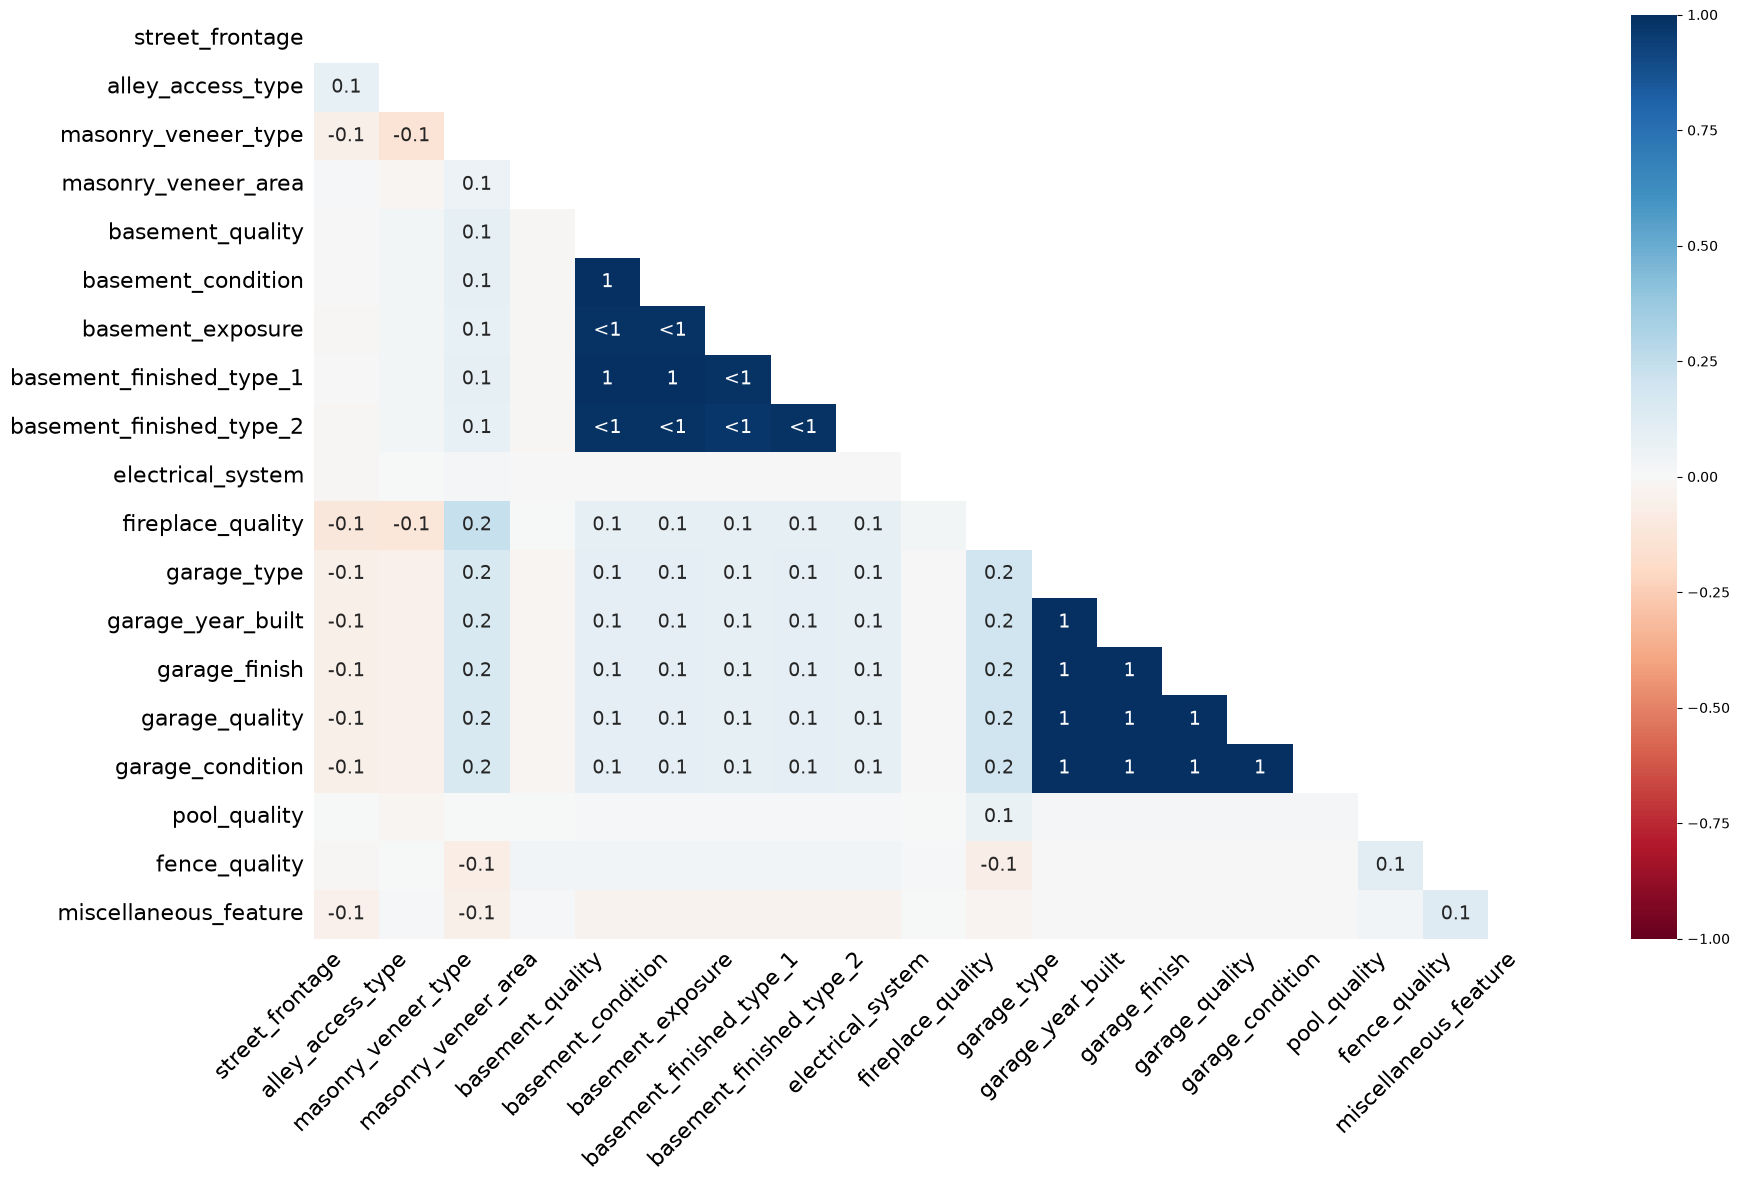

In [109]:
msno.heatmap(df_train)
plt.show()

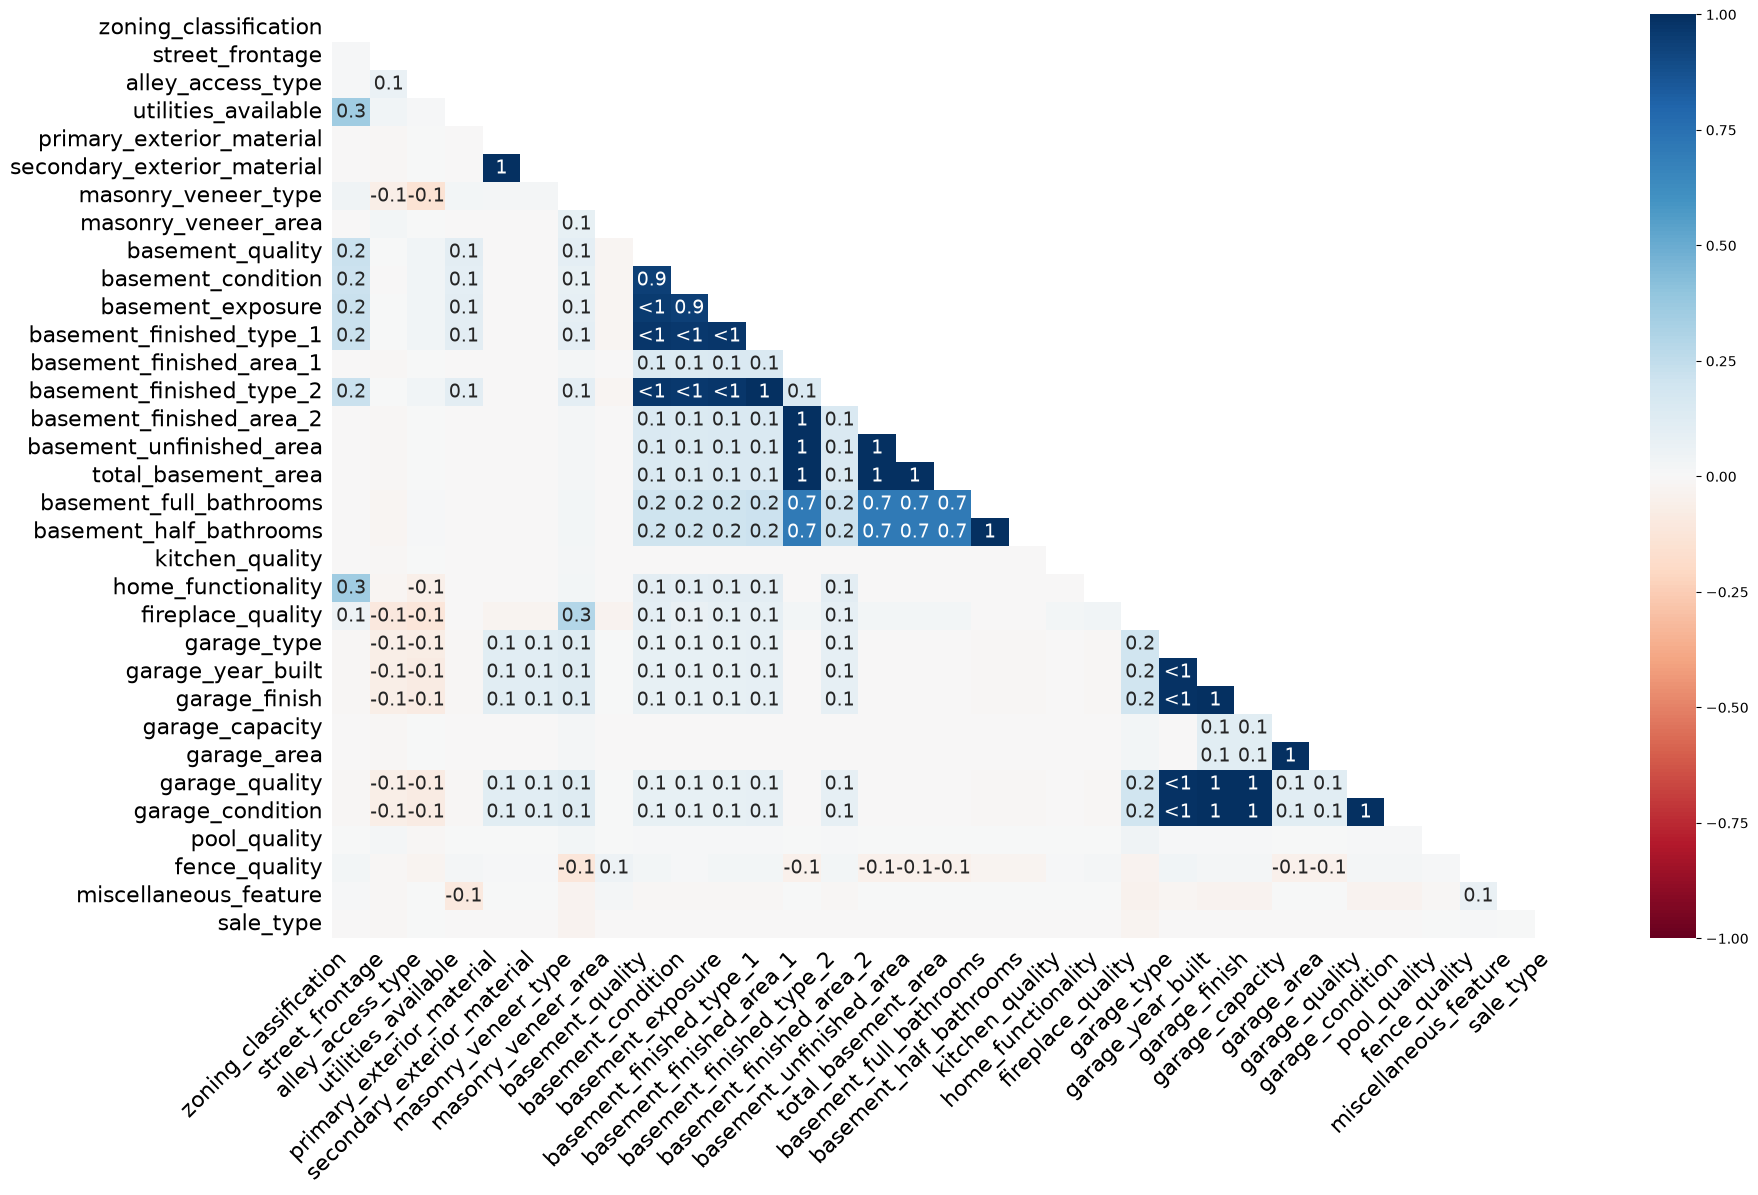

In [110]:
msno.heatmap(df_test)
plt.show()

In [111]:
"""

Replace missing numerical values with 0 when missing means the property
does not have that feature (e.g., no masonry veneer).

Replace missing categorical values with "Missing" to represent
the absence of a feature (e.g., no pool, fence, or garage).

We keep these columns because the absence of a feature is useful
information that may help the model predict house prices.
Dropping them would cause us to lose potentially valuable information.

"""

df_train[absence_categorical] = df_train[absence_categorical].fillna("Missing")
df_test[absence_categorical] = df_test[absence_categorical].fillna("Missing")

print("Absent categorical values in train dataset after imputation:\n",
      df_train[absence_categorical].isnull().sum())

print("\n" + "="*100 + "\n")

print("Absent categorical values in test dataset after imputation:\n",
      df_test[absence_categorical].isnull().sum())

Absent categorical values in train dataset after imputation:
 pool_quality                0
miscellaneous_feature       0
alley_access_type           0
fence_quality               0
fireplace_quality           0
garage_type                 0
garage_finish               0
garage_quality              0
garage_condition            0
basement_quality            0
basement_condition          0
basement_exposure           0
basement_finished_type_1    0
basement_finished_type_2    0
masonry_veneer_type         0
dtype: int64


Absent categorical values in test dataset after imputation:
 pool_quality                0
miscellaneous_feature       0
alley_access_type           0
fence_quality               0
fireplace_quality           0
garage_type                 0
garage_finish               0
garage_quality              0
garage_condition            0
basement_quality            0
basement_condition          0
basement_exposure           0
basement_finished_type_1    0
basement_finished_type

In [112]:
df_train[absence_numerical] = df_train[absence_numerical].fillna(0)
df_test[absence_numerical] = df_test[absence_numerical].fillna(0)
print("absent numerical values in train dataset after imputation: \n", df_train[absence_numerical].isnull().sum())
print("\n========================================================================================================\n")
print("absent numerical values in test dataset after imputation: \n", df_test[absence_numerical].isnull().sum())

absent numerical values in train dataset after imputation: 
 masonry_veneer_area    0
garage_year_built      0
dtype: int64


absent numerical values in test dataset after imputation: 
 masonry_veneer_area    0
garage_year_built      0
dtype: int64


In [113]:
df_train.isnull().sum().sort_values(ascending = False)

street_frontage          259
electrical_system          1
property_id                0
zoning_classification      0
dwelling_class             0
                        ... 
month_sold                 0
year_sold                  0
sale_type                  0
sale_condition             0
sale_price                 0
Length: 81, dtype: int64

In [114]:
remaining_null_counts_test = df_test.isnull().sum().sort_values(ascending = False)
remaining_null_counts_test[remaining_null_counts_test>0]

street_frontage                227
zoning_classification            4
utilities_available              2
basement_full_bathrooms          2
basement_half_bathrooms          2
home_functionality               2
garage_capacity                  1
basement_finished_area_2         1
secondary_exterior_material      1
basement_finished_area_1         1
basement_unfinished_area         1
total_basement_area              1
primary_exterior_material        1
sale_type                        1
kitchen_quality                  1
garage_area                      1
dtype: int64

In [115]:
# Find columns with missing values in either dataset
missing_columns = set(df_train.columns[df_train.isnull().any()]) | \
                  set(df_test.columns[df_test.isnull().any()])

# Don't process the target column
missing_columns.discard("sale_price")

for col in missing_columns:

    # Check whether the column is numeric
    if pd.api.types.is_numeric_dtype(df_train[col]):

        # Calculate IQR to detect outliers using training data
        Q1 = df_train[col].quantile(0.25)
        Q3 = df_train[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR

        outliers = df_train[col][
            (df_train[col] < lower_limit) |
            (df_train[col] > upper_limit)
        ]

        # Choose median or mean
        if len(outliers) > 0:
            fill_value = df_train[col].median()
            print(f"{col}: Outliers found -> Median")
        else:
            fill_value = df_train[col].mean()
            print(f"{col}: No outliers -> Mean")

    else:
        # Use mode for categorical columns
        fill_value = df_train[col].mode()[0]
        print(f"{col}: Categorical -> Mode")

    # Apply the training-derived value to both datasets
    df_train[col] = df_train[col].fillna(fill_value)
    df_test[col] = df_test[col].fillna(fill_value)

street_frontage: Outliers found -> Median
basement_finished_area_2: Outliers found -> Median
electrical_system: Categorical -> Mode
basement_finished_area_1: Outliers found -> Median
zoning_classification: Categorical -> Mode
kitchen_quality: Categorical -> Mode
home_functionality: Categorical -> Mode
utilities_available: Categorical -> Mode
basement_half_bathrooms: Outliers found -> Median
total_basement_area: Outliers found -> Median
secondary_exterior_material: Categorical -> Mode
sale_type: Categorical -> Mode
primary_exterior_material: Categorical -> Mode
basement_full_bathrooms: Outliers found -> Median
garage_capacity: Outliers found -> Median
basement_unfinished_area: Outliers found -> Median
garage_area: Outliers found -> Median


In [116]:
print("Missing values in trainging dataset after final imputation: \n", df_train.isnull().sum().sum())
print("Missing values in trainging dataset after final imputation: \n", df_test.isnull().sum().sum())

Missing values in trainging dataset after final imputation: 
 0
Missing values in trainging dataset after final imputation: 
 0


In [117]:
# Check duplicate rows
print("Training duplicates:", df_train.duplicated().sum())
print("Test duplicates:", df_test.duplicated().sum())

# Check duplicate property IDs
print("Duplicate training IDs:", df_train["property_id"].duplicated().sum())
print("Duplicate test IDs:", df_test["property_id"].duplicated().sum())

Training duplicates: 0
Test duplicates: 0
Duplicate training IDs: 0
Duplicate test IDs: 0


In [118]:
df_train["sale_price"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: sale_price, dtype: float64

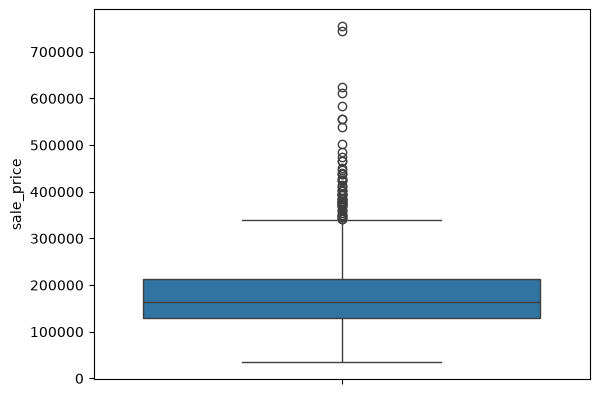

In [119]:
sns.boxplot(df_train['sale_price'])
plt.show()

In [120]:
print("Average house price: ", df_train['sale_price'].mean().round(3))
print("Most frequently occuring house price: ", df_train['sale_price'].mode()[0])
print("median house price: ", df_train['sale_price'].median())
print("spread house price: ", df_train['sale_price'].var())
print("Maximum house price: ", df_train['sale_price'].max())
print( "Minimum house price: ", df_train['sale_price'].min())
print("Range of house prices: ", df_train['sale_price'].max()-df_train['sale_price'].min())

Average house price:  180921.196
Most frequently occuring house price:  140000
median house price:  163000.0
spread house price:  6311111264.297448
Maximum house price:  755000
Minimum house price:  34900
Range of house prices:  720100


In [121]:
q1 = np.quantile(df_train['sale_price'], 0.25)
q3 = np.quantile(df_train['sale_price'], 0.75)

iqr = q3 - q1

lower_limit = q1 - (1.5 * iqr)
upper_limit = q3 + (1.5 * iqr)

outliers = df_train[(df_train['sale_price'] < lower_limit) |
                    (df_train['sale_price'] > upper_limit)]

print("Number of outliers:", len(outliers))
print(outliers[['sale_price']])


Number of outliers: 61
      sale_price
11        345000
53        385000
58        438780
112       383970
151       372402
...          ...
1268      381000
1353      410000
1373      466500
1388      377500
1437      394617

[61 rows x 1 columns]


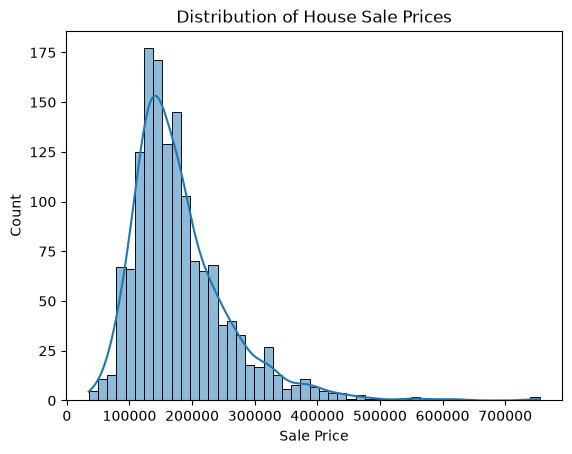

In [122]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df_train["sale_price"], kde=True)
plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.show()

In [123]:
correlation = df_train.corr(numeric_only=True)["sale_price"].sort_values(
    ascending=False
)

print(correlation)

sale_price                     1.000000
overall_quality                0.790982
above_ground_living_area       0.708624
garage_capacity                0.640409
garage_area                    0.623431
total_basement_area            0.613581
first_floor_area               0.605852
full_bathrooms                 0.560664
total_rooms_above_ground       0.533723
year_built                     0.522897
year_remodeled                 0.507101
masonry_veneer_area            0.472614
number_of_fireplaces           0.466929
basement_finished_area_1       0.386420
street_frontage                0.334771
wood_deck_area                 0.324413
second_floor_area              0.319334
open_porch_area                0.315856
half_bathrooms                 0.284108
lot_area                       0.263843
garage_year_built              0.261366
basement_full_bathrooms        0.227122
basement_unfinished_area       0.214479
bedrooms_above_ground          0.168213
screen_porch_area              0.111447


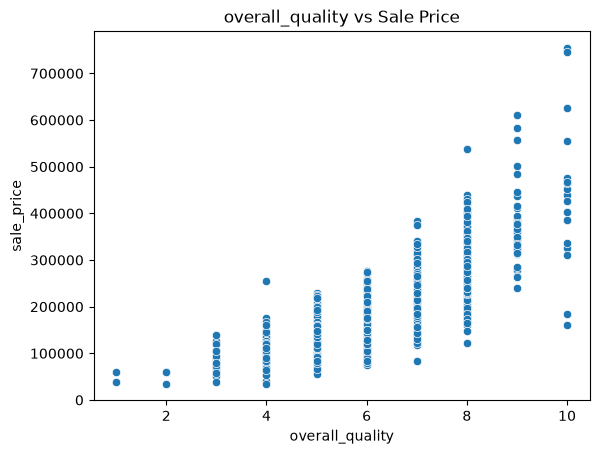

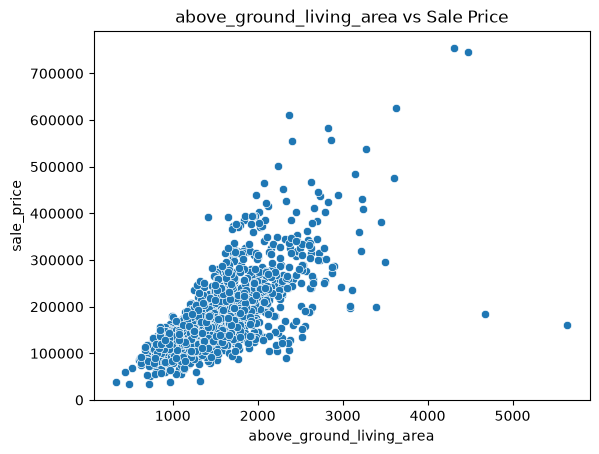

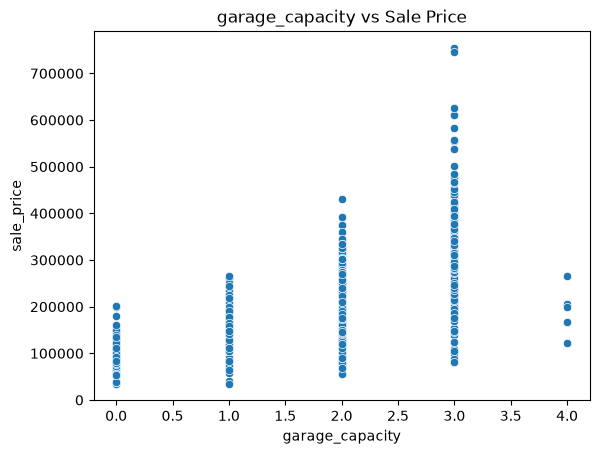

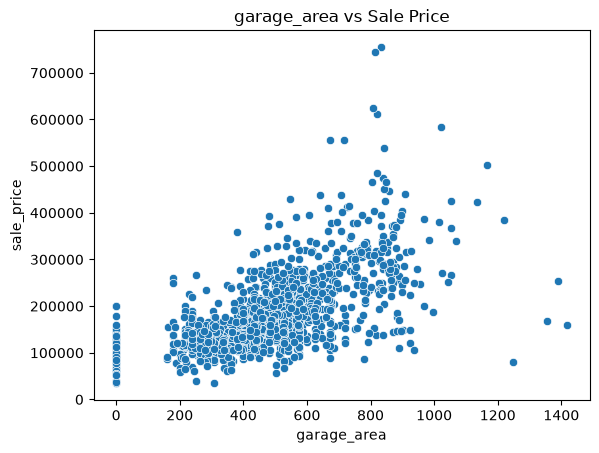

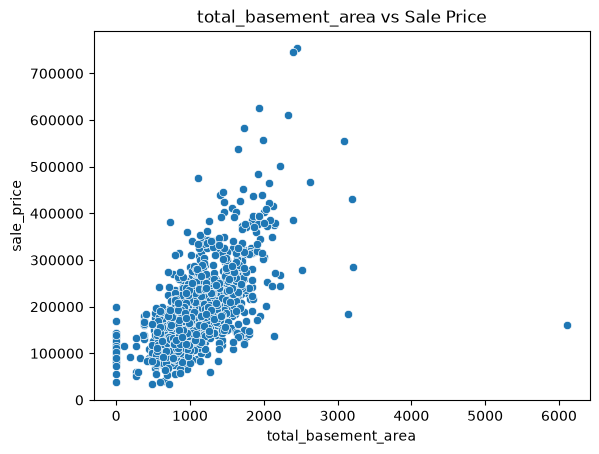

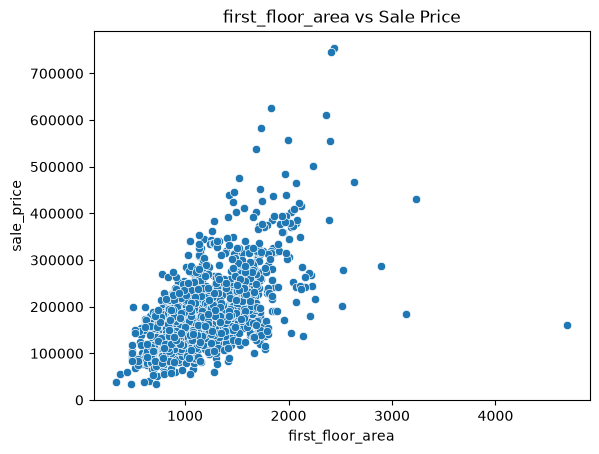

In [124]:
top_features = [
    "overall_quality",
    "above_ground_living_area",
    "garage_capacity",
    "garage_area",
    "total_basement_area",
    "first_floor_area"
]

for col in top_features:
    sns.scatterplot(data=df_train, x=col, y="sale_price")
    plt.title(f"{col} vs Sale Price")
    plt.show()

In [125]:
from sklearn.model_selection import train_test_split

X = df_train.drop(columns=["sale_price", "property_id"])
y = df_train["sale_price"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [126]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["str", "category"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 36
Categorical features: 43


In [127]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [128]:
X_train_processed = preprocessor.fit_transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_valid_processed.shape)

Training shape: (1168, 300)
Validation shape: (292, 300)


In [129]:
import numpy as np

y_train_original = y_train
y_valid_original = y_valid

y_train_log = np.log1p(y_train)
y_valid_log = np.log1p(y_valid)

In [130]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Experiment 1: Original target
linear_original = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_original.fit(X_train, y_train_original)

pred_original = linear_original.predict(X_valid)


# Experiment 2: Log-transformed target
linear_log = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_log.fit(X_train, y_train_log)

pred_log = linear_log.predict(X_valid)

# Convert log predictions back to original prices
pred_log_original = np.expm1(pred_log)

In [131]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_model(y_true, predictions, experiment):

    rmse = np.sqrt(mean_squared_error(y_true, predictions))
    mae = mean_absolute_error(y_true, predictions)
    r2 = r2_score(y_true, predictions)

    print(f"\n{experiment}")
    print("RMSE:", round(rmse, 2))
    print("MAE:", round(mae, 2))
    print("R2:", round(r2, 4))


evaluate_model(y_valid_original, pred_original, "Original Target")
evaluate_model(y_valid_original, pred_log_original, "Log Transformed Target")


Original Target
RMSE: 65335.28
MAE: 21100.22
R2: 0.4435

Log Transformed Target
RMSE: 22873.09
MAE: 15074.57
R2: 0.9318


In [132]:
pred_original = np.maximum(pred_original, 0)
pred_log_original = np.maximum(pred_log_original, 0)


(pred_original < 0).sum()

np.int64(0)

In [133]:
from sklearn.metrics import root_mean_squared_log_error

# Original target model
rmsle_original = root_mean_squared_log_error(
    y_valid_original, pred_original
)

# Log-transformed target model
rmsle_log = root_mean_squared_log_error(
    y_valid_original, pred_log_original
)

print("Original Target RMSLE:", round(rmsle_original, 5))
print("Log Target RMSLE:", round(rmsle_log, 5))

Original Target RMSLE: 0.72357
Log Target RMSLE: 0.13153


In [134]:
# Record our baseline
# - Algorithm: Linear Regression
# - Best target treatment: Log-transformed
# - Validation RMSLE: 0.13153

In [135]:
from sklearn.linear_model import Ridge

# Experiment 1: Original target
ridge_original = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

ridge_original.fit(X_train, y_train_original)
ridge_pred_original = ridge_original.predict(X_valid)


# Experiment 2: Log-transformed target
ridge_log = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

ridge_log.fit(X_train, y_train_log)
ridge_pred_log = ridge_log.predict(X_valid)

# Convert predictions back to original price scale
ridge_pred_log_original = np.expm1(ridge_pred_log)

In [136]:
evaluate_model(
    y_valid_original,
    ridge_pred_original,
    "Ridge - Original Target"
)

evaluate_model(
    y_valid_original,
    ridge_pred_log_original,
    "Ridge - Log Target"
)


Ridge - Original Target
RMSE: 29748.3
MAE: 19137.66
R2: 0.8846

Ridge - Log Target
RMSE: 23853.69
MAE: 15747.48
R2: 0.9258


In [137]:
from sklearn.metrics import root_mean_squared_log_error

print(
    "Ridge Original RMSLE:",
    root_mean_squared_log_error(
        y_valid_original, ridge_pred_original
    )
)

print(
    "Ridge Log RMSLE:",
    root_mean_squared_log_error(
        y_valid_original, ridge_pred_log_original
    )
)

Ridge Original RMSLE: 0.1652581267408289
Ridge Log RMSLE: 0.13151799825284513


In [138]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
import numpy as np

# Experiment 1: Original target
rf_original = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

rf_original.fit(X_train, y_train_original)

rf_pred_original = rf_original.predict(X_valid)


# Experiment 2: Log-transformed target
rf_log = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

rf_log.fit(X_train, y_train_log)

rf_pred_log = rf_log.predict(X_valid)

# Convert predictions back to original price scale
rf_pred_log_original = np.expm1(rf_pred_log)

In [139]:
evaluate_model(
    y_valid_original,
    rf_pred_original,
    "Random Forest - Original Target"
)

evaluate_model(
    y_valid_original,
    rf_pred_log_original,
    "Random Forest - Log Target"
)


Random Forest - Original Target
RMSE: 28661.66
MAE: 17446.27
R2: 0.8929

Random Forest - Log Target
RMSE: 29295.06
MAE: 17366.49
R2: 0.8881


In [140]:
from sklearn.metrics import root_mean_squared_log_error

print(
    "Random Forest Original RMSLE:",
    root_mean_squared_log_error(
        y_valid_original, rf_pred_original
    )
)

print(
    "Random Forest Log RMSLE:",
    root_mean_squared_log_error(
        y_valid_original, rf_pred_log_original
    )
)

Random Forest Original RMSLE: 0.15246529845104334
Random Forest Log RMSLE: 0.1456121441772313


In [141]:
from sklearn.ensemble import GradientBoostingRegressor

# Experiment 1: Original target
gb_original = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_original.fit(X_train, y_train_original)
gb_pred_original = gb_original.predict(X_valid)


# Experiment 2: Log-transformed target
gb_log = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_log.fit(X_train, y_train_log)
gb_pred_log = gb_log.predict(X_valid)

gb_pred_log_original = np.expm1(gb_pred_log)

In [142]:
evaluate_model(
    y_valid_original,
    gb_pred_original,
    "Gradient Boosting - Original"
)

evaluate_model(
    y_valid_original,
    gb_pred_log_original,
    "Gradient Boosting - Log"
)


Gradient Boosting - Original
RMSE: 27008.36
MAE: 16977.0
R2: 0.9049

Gradient Boosting - Log
RMSE: 28579.81
MAE: 16660.67
R2: 0.8935


In [143]:
print(
    "Gradient Boosting Original RMSLE:",
    root_mean_squared_log_error(
        y_valid_original, gb_pred_original
    )
)

print(
    "Gradient Boosting Log RMSLE:",
    root_mean_squared_log_error(
        y_valid_original, gb_pred_log_original
    )
)

Gradient Boosting Original RMSLE: 0.13850761188108862
Gradient Boosting Log RMSLE: 0.13353364882005744


In [144]:
from xgboost import XGBRegressor
# Experiment 1: Original target
xgb_original = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ))
])

xgb_original.fit(X_train, y_train_original)

xgb_pred_original = xgb_original.predict(X_valid)


# Experiment 2: Log-transformed target
xgb_log = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ))
])

xgb_log.fit(X_train, y_train_log)

xgb_pred_log = xgb_log.predict(X_valid)

# Convert predictions back to original prices
xgb_pred_log_original = np.expm1(xgb_pred_log)

In [145]:
evaluate_model(
    y_valid_original,
    xgb_pred_original,
    "XGBoost - Original Target"
)

evaluate_model(
    y_valid_original,
    xgb_pred_log_original,
    "XGBoost - Log Target"
)


XGBoost - Original Target
RMSE: 25154.13
MAE: 16164.3
R2: 0.9175

XGBoost - Log Target
RMSE: 26768.04
MAE: 15682.47
R2: 0.9066


In [146]:
from sklearn.metrics import root_mean_squared_log_error

print(
    "XGBoost Original RMSLE:",
    root_mean_squared_log_error(
        y_valid_original,
        np.maximum(xgb_pred_original, 0)
    )
)

print(
    "XGBoost Log RMSLE:",
    root_mean_squared_log_error(
        y_valid_original,
        np.maximum(xgb_pred_log_original, 0)
    )
)

XGBoost Original RMSLE: 0.13282041251659393
XGBoost Log RMSLE: 0.12877367436885834


In [147]:
import numpy as np

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    root_mean_squared_log_error
)

# 1. Create model pipeline
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ))
])

# 2. Train using log-transformed target
xgb_model.fit(X_train, np.log1p(y_train))

# 3. Predict and convert back to original prices
y_pred_xgb = np.expm1(xgb_model.predict(X_valid))

# 4. Evaluate
rmse = np.sqrt(mean_squared_error(y_valid, y_pred_xgb))
mae = mean_absolute_error(y_valid, y_pred_xgb)
r2 = r2_score(y_valid, y_pred_xgb)
rmsle = root_mean_squared_log_error(
    y_valid, np.maximum(y_pred_xgb, 0)
)

print("XGBoost - Log Transformed Target")
print(f"RMSE:  {rmse:.2f}")
print(f"MAE:   {mae:.2f}")
print(f"R²:    {r2:.4f}")
print(f"RMSLE: {rmsle:.5f}")

XGBoost - Log Transformed Target
RMSE:  26768.04
MAE:   15682.47
R²:    0.9066
RMSLE: 0.12877


In [148]:
from sklearn.model_selection import RandomizedSearchCV

# Parameters to experiment with
param_grid = {
    "model__n_estimators": [300, 500, 700, 1000],
    "model__learning_rate": [0.01, 0.02, 0.03, 0.05],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_child_weight": [1, 3, 5],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

# Randomized search
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=25,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train using log-transformed target
random_search.fit(X_train, np.log1p(y_train))

# Best model
best_xgb_model = random_search.best_estimator_

# Predict on untouched validation data
y_pred_tuned = np.expm1(best_xgb_model.predict(X_valid))

# Evaluate
y_pred_tuned = np.maximum(y_pred_tuned, 0)

print("Best parameters:", random_search.best_params_)
print("Best CV RMSLE:", -random_search.best_score_)

print("\nTuned XGBoost Validation Results")
print("RMSE:", np.sqrt(mean_squared_error(y_valid, y_pred_tuned)))
print("MAE:", mean_absolute_error(y_valid, y_pred_tuned))
print("R²:", r2_score(y_valid, y_pred_tuned))
print("RMSLE:", root_mean_squared_log_error(y_valid, y_pred_tuned))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best parameters: {'model__subsample': 0.8, 'model__n_estimators': 700, 'model__min_child_weight': 1, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.9}
Best CV RMSLE: 0.12484576884042842

Tuned XGBoost Validation Results
RMSE: 25611.983445254686
MAE: 14976.71875
R²: 0.9144790172576904
RMSLE: 0.12636861205101013


In [149]:
# Train final model on all available training data
X_full = df_train.drop(columns=["sale_price", "property_id"])
y_full = np.log1p(df_train["sale_price"])

final_model = best_xgb_model
final_model.fit(X_full, y_full)

print("Final XGBoost model trained successfully!")

Final XGBoost model trained successfully!


In [150]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    root_mean_squared_log_error
)

# 1. Evaluate on validation data
valid_predictions = np.expm1(
    final_model.predict(X_valid)
)

valid_predictions = np.maximum(valid_predictions, 0)

print("Final XGBoost Validation Results")
print("RMSE:", np.sqrt(mean_squared_error(y_valid, valid_predictions)))
print("MAE:", mean_absolute_error(y_valid, valid_predictions))
print("R²:", r2_score(y_valid, valid_predictions))
print("RMSLE:", root_mean_squared_log_error(y_valid, valid_predictions))


# 2. Predict house prices for test data
X_test = df_test.drop(columns=["property_id"])

test_predictions = np.expm1(final_model.predict(X_test))
test_predictions = np.maximum(test_predictions, 0)

# 3. Create predictions dataframe
submission = pd.DataFrame({
    "property_id": df_test["property_id"],
    "sale_price": test_predictions
})

print("\nTest Predictions:")
print(submission.head())

print("\nTotal predictions:", len(submission))

Final XGBoost Validation Results
RMSE: 10939.60584299087
MAE: 7211.8818359375
R²: 0.9843976497650146
RMSLE: 0.05262145400047302

Test Predictions:
   property_id     sale_price
0         1461  125163.101562
1         1462  157107.531250
2         1463  190064.625000
3         1464  192701.046875
4         1465  180752.218750

Total predictions: 1459


In [151]:
from sklearn.base import clone
import numpy as np
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    root_mean_squared_log_error
)

# Fresh copy of tuned model
validation_model = clone(best_xgb_model)

# Train only on training split
validation_model.fit(X_train, np.log1p(y_train))

# Predict validation data
valid_predictions = np.expm1(
    validation_model.predict(X_valid)
)

valid_predictions = np.maximum(valid_predictions, 0)

# Evaluate
print("Corrected Validation Results")
print("RMSE:", np.sqrt(mean_squared_error(y_valid, valid_predictions)))
print("MAE:", mean_absolute_error(y_valid, valid_predictions))
print("R²:", r2_score(y_valid, valid_predictions))
print("RMSLE:", root_mean_squared_log_error(y_valid, valid_predictions))

Corrected Validation Results
RMSE: 25611.983445254686
MAE: 14976.71875
R²: 0.9144790172576904
RMSLE: 0.12636861205101013


In [152]:
import numpy as np
import pandas as pd
import joblib

# 1. Generate final test predictions
test_predictions = np.expm1(
    final_model.predict(
        df_test.drop(columns=["property_id"])
    )
)

test_predictions = np.maximum(test_predictions, 0)

# 2. Create Kaggle submission
submission = pd.DataFrame({
    "Id": df_test["property_id"],
    "SalePrice": test_predictions
})

# 3. Save submission CSV
submission.to_csv("submission.csv", index=False)

# 4. Save trained model
joblib.dump(final_model, "house_price_xgb_model.pkl")

print("Files saved successfully!")
print("Submission shape:", submission.shape)
print("\nSubmission preview:")
print(submission.head())

Files saved successfully!
Submission shape: (1459, 2)

Submission preview:
     Id      SalePrice
0  1461  125163.101562
1  1462  157107.531250
2  1463  190064.625000
3  1464  192701.046875
4  1465  180752.218750
